<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77338 entries, 0 to 77337
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    77338 non-null  int64  
 1   V1      77338 non-null  float64
 2   V2      77338 non-null  float64
 3   V3      77338 non-null  float64
 4   V4      77338 non-null  float64
 5   V5      77338 non-null  float64
 6   V6      77338 non-null  float64
 7   V7      77338 non-null  float64
 8   V8      77338 non-null  float64
 9   V9      77338 non-null  float64
 10  V10     77338 non-null  float64
 11  V11     77338 non-null  float64
 12  V12     77338 non-null  float64
 13  V13     77338 non-null  float64
 14  V14     77337 non-null  float64
 15  V15     77337 non-null  float64
 16  V16     77337 non-null  float64
 17  V17     77337 non-null  float64
 18  V18     77337 non-null  float64
 19  V19     77337 non-null  float64
 20  V20     77337 non-null  float64
 21  V21     77337 non-null  float64
 22

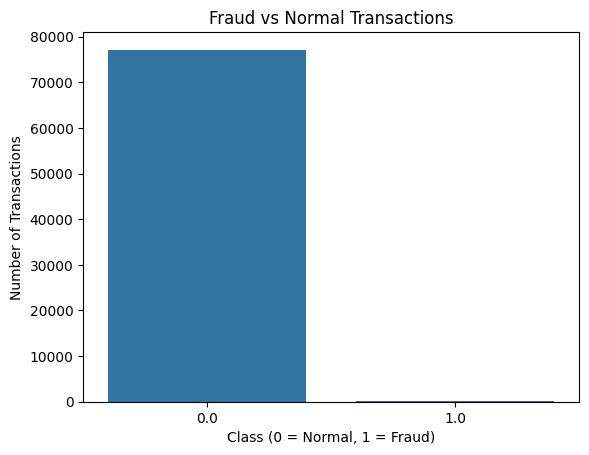

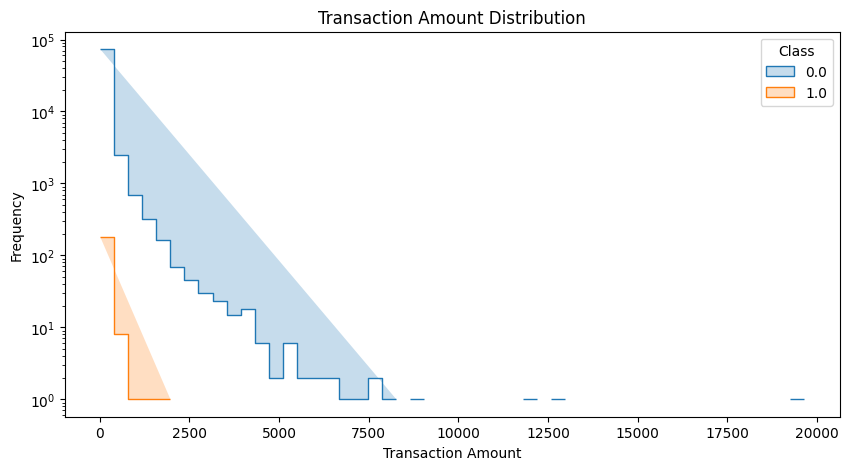

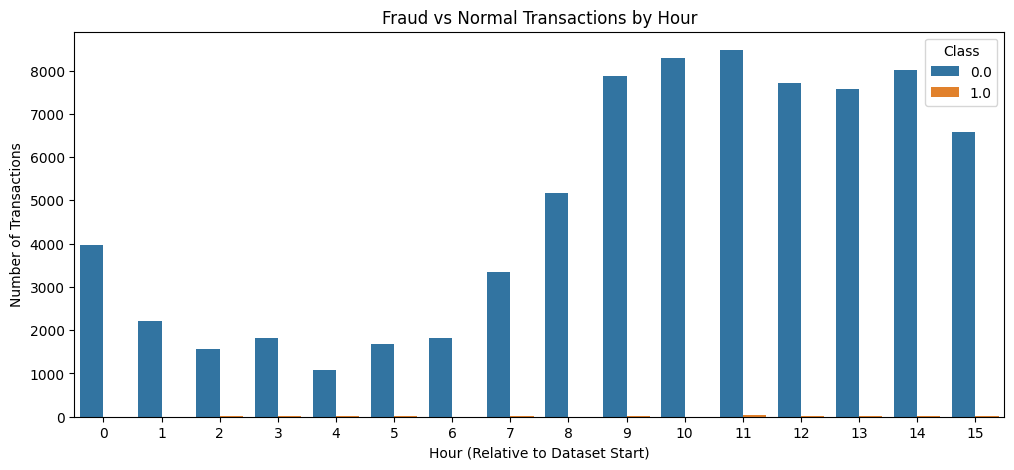

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

df = pd.read_csv('creditcard.csv')

df.head()

df.shape

df.info()

df.isnull().sum().sum()

df.describe()

df['Class'].value_counts()

fraud_percentage = df['Class'].value_counts(normalize=True) * 100

print(fraud_percentage)

sns.countplot(data=df, x='Class')

plt.title('Fraud vs Normal Transactions')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Amount',
    hue='Class',
    bins=50,
    log_scale=(False, True),
    element='step'
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

df['Hour'] = (df['Time'] // 3600) % 24

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x='Hour',
    hue='Class'
)

plt.title('Fraud vs Normal Transactions by Hour')
plt.xlabel('Hour (Relative to Dataset Start)')
plt.ylabel('Number of Transactions')
plt.show()

#Why Is Accuracy Misleading?
Accuracy can be misleading when working with highly imbalanced datasets. In this dataset, approximately 99.83% of transactions are legitimate and only 0.17% are fraudulent.

A model that predicts every transaction as normal could achieve around 99.83% accuracy without detecting a single fraudulent transaction.

Therefore, accuracy alone cannot measure the effectiveness of a fraud detection model. We should also use Precision, Recall, F1-Score, and ROC-AUC to evaluate its performance.

Features: (77337, 30)
Target: (77337,)
Training Data:
Class
0.0    61719
1.0      150
Name: count, dtype: int64

Testing Data:
Class
0.0    15430
1.0       38
Name: count, dtype: int64

Logistic Regression Evaluation
----------------------------------------
Accuracy: 0.9873933281613654
Precision: 0.14798206278026907
Recall: 0.868421052631579
F1-Score: 0.25287356321839083
ROC-AUC: 0.9593495241668657

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99     15430
         1.0       0.15      0.87      0.25        38

    accuracy                           0.99     15468
   macro avg       0.57      0.93      0.62     15468
weighted avg       1.00      0.99      0.99     15468


Random Forest Evaluation
----------------------------------------
Accuracy: 0.9993535040082752
Precision: 0.9117647058823529
Recall: 0.8157894736842105
F1-Score: 0.8611111111111112
ROC-AUC: 0.9504690111539379

Classification Report:
             

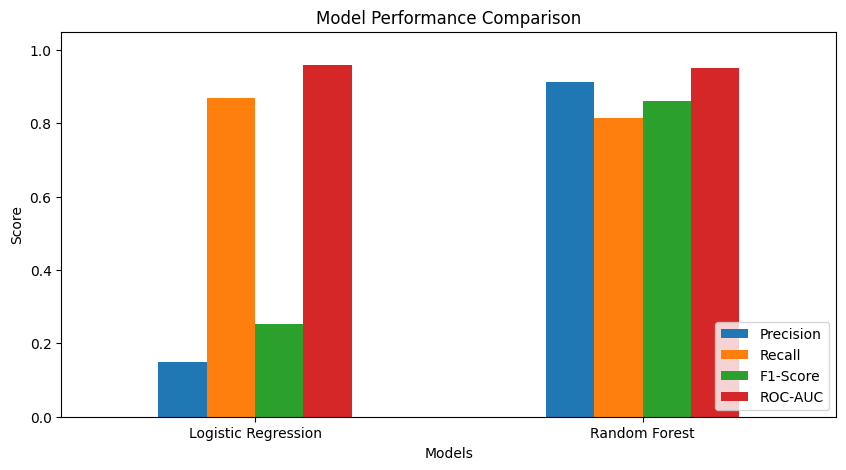

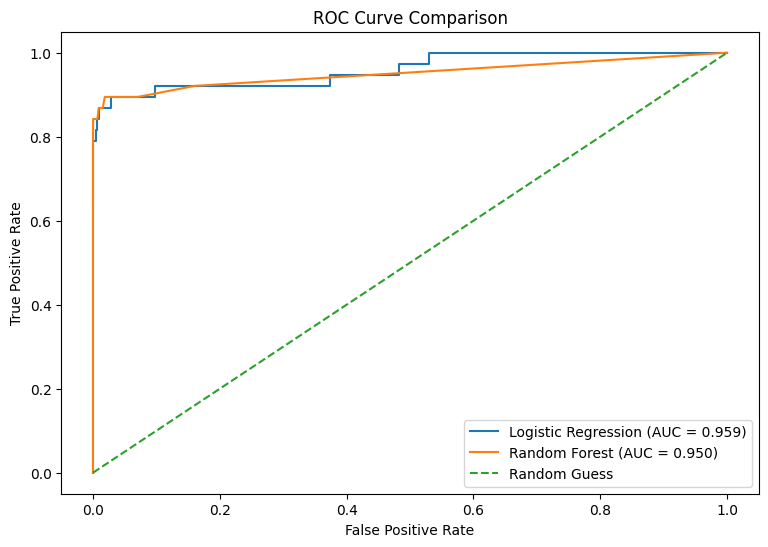

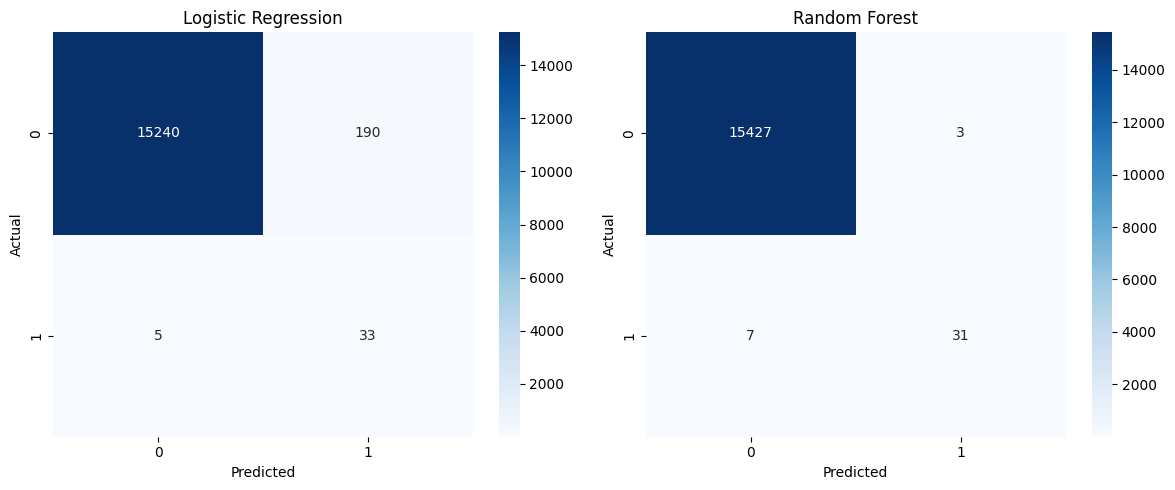

In [18]:
# Clean the data by dropping rows with missing values in the target column
df_cleaned = df.dropna(subset=['Class'])

X = df_cleaned.drop(['Class', 'Hour'], axis=1)
y = df_cleaned['Class']

print("Features:", X.shape)
print("Target:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:")
print(y_train.value_counts())

print("\nTesting Data:")
print(y_test.value_counts())

smote = SMOTE(
    sampling_strategy=0.5,
    random_state=42
)


lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(
        sampling_strategy=0.5,
        random_state=42
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

lr_probabilities = lr_model.predict_proba(X_test)[:, 1]


rf_model = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(
        sampling_strategy=0.5,
        random_state=42
    )),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]


def evaluate_model(name, y_true, predictions, probabilities):
    print(f"\n{name} Evaluation")
    print("-" * 40)

    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Precision:", precision_score(y_true, predictions))
    print("Recall:", recall_score(y_true, predictions))
    print("F1-Score:", f1_score(y_true, predictions))
    print("ROC-AUC:", roc_auc_score(y_true, probabilities))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        predictions,
        zero_division=0
    ))


evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions)
    ],
    'F1-Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, lr_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

print(results)

results.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Models')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.show()

lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

plt.figure(figsize=(9, 6))
plt.plot(
    lr_fpr,
    lr_tpr,
    label=f"Logistic Regression (AUC = {roc_auc_score(y_test, lr_probabilities):.3f})"
)
plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, rf_probabilities):.3f})"
)
plt.plot([0, 1], [0, 1], '--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, predictions, name in zip(
    axes,
    [lr_predictions, rf_predictions],
    ['Logistic Regression', 'Random Forest']
):
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

#Which Metric Matters Most for Fraud Detection?
##Recall vs Precision :
Recall is particularly important in fraud detection because it measures how many actual fraudulent transactions the model successfully identifies.

For example, if there are 100 fraudulent transactions and the model detects 90, its recall is 90%.

However, Precision is also important because it measures how many transactions predicted as fraud are actually fraudulent.

There is a trade-off between these two metrics:
- High Recall means fewer fraudulent transactions are missed, but more legitimate transactions may be flagged.
- High Precision means fewer false fraud alerts, but some actual fraud cases may be missed.

For fraud detection, I would prioritize Recall while maintaining a reasonable Precision score. This helps reduce financial losses without creating too many unnecessary alerts.

#Feature Importance Explanation
Feature importance helps us identify which variables contribute most to the model's predictions. This analysis provides a better understanding of the transaction patterns that help distinguish fraudulent transactions from normal ones.

These importance scores show predictive contribution, not necessarily a direct cause of fraud.

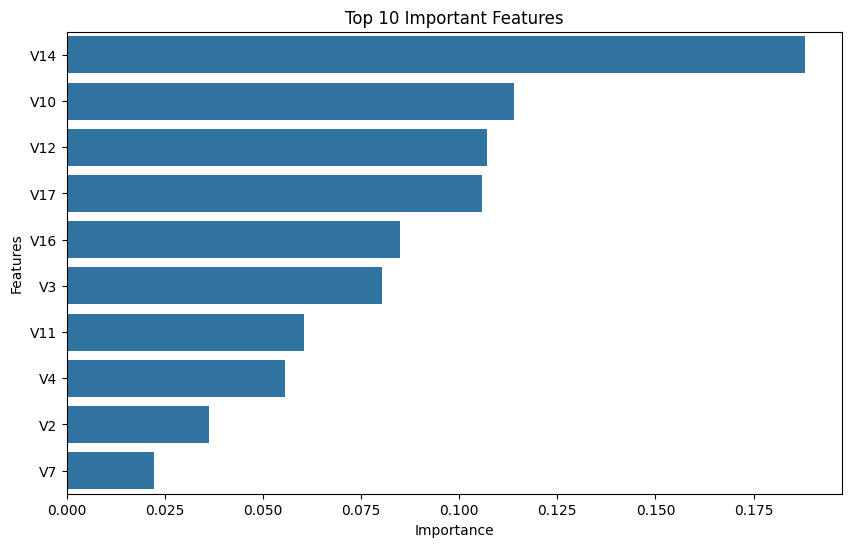

In [19]:
rf_classifier = rf_model.named_steps['classifier']

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(10)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

#Scalability – Handling 1 Million Transactions Per Hour
##Scalability :
If this fraud detection system needs to process one million transactions per hour, the system would need an efficient and scalable infrastructure.

Some improvements would include:
1. Real-Time Processing: Use Apache Kafka to receive and manage incoming transactions.
2. Distributed Computing: Use Apache Spark or similar technologies to process large amounts of data.
3. Model Optimization: Optimize the trained model to reduce prediction time.
4. Cloud Deployment: Use scalable cloud infrastructure to handle increasing transaction volumes.
5. Continuous Monitoring: Monitor model performance and retrain it when new fraud patterns appear.

One million transactions per hour is approximately 278 transactions per second. A production system would require efficient prediction services, low-latency processing, monitoring, and reliable infrastructure to handle this workload.